<a href="https://colab.research.google.com/github/ykidnwg/PCD_4_Peningkatan_Kualitas_Citra/blob/main/PCD_4_Peningkatan_Kualitas_Citra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Sel 1 — Import library**

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from skimage import data, img_as_ubyte
from skimage.metrics import structural_similarity as ssim

print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


**Sel 2 — Menyiapkan citra studi kasus**

Silakan upload gambar dari komputer Anda.


Saving OIP.jpg to OIP.jpg
Nama gambar: OIP.jpg
Ukuran gambar: (234, 300)
Gambar berhasil dibaca!


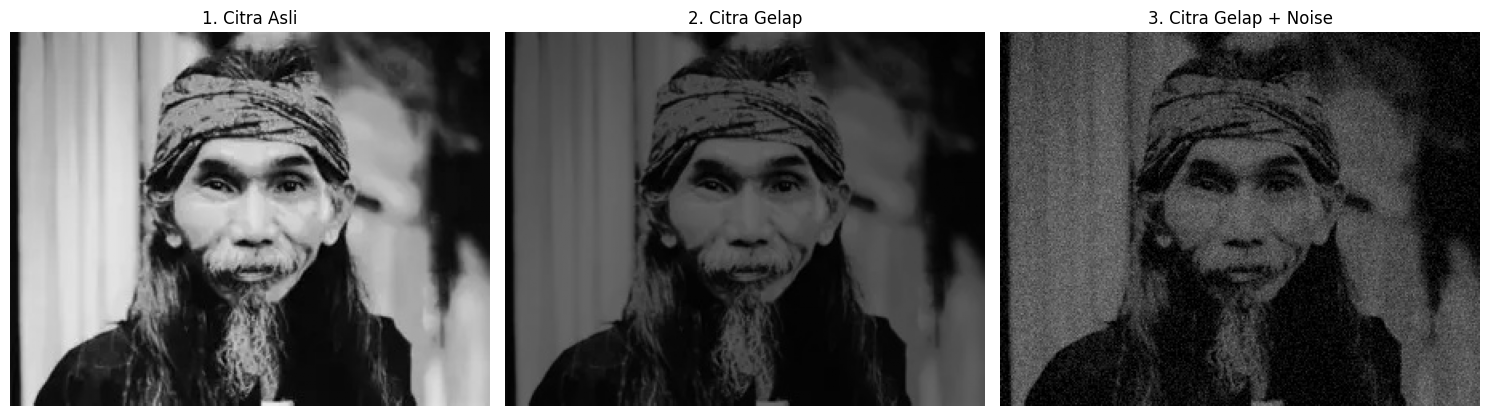

In [2]:
from google.colab import files
from PIL import Image
from io import BytesIO
import numpy as np
import matplotlib.pyplot as plt

# 1. Memilih dan mengunggah gambar
print("Silakan upload gambar dari komputer Anda.")
uploaded = files.upload()

if not uploaded:
    raise ValueError("Belum ada gambar yang diunggah.")

# 2. Membaca gambar yang dipilih
nama_file = next(iter(uploaded))

gambar = Image.open(
    BytesIO(uploaded[nama_file])
).convert("RGB")

# Mengubah gambar berwarna menjadi grayscale
citra_asli = np.array(
    gambar.convert("L"),
    dtype=np.uint8
)

print("Nama gambar:", nama_file)
print("Ukuran gambar:", citra_asli.shape)
print("Gambar berhasil dibaca!")

# 3. Membuat citra gelap
citra_gelap = np.clip(
    citra_asli.astype(np.float32) * 0.45,
    0, 255
).astype(np.uint8)

# 4. Menambahkan noise Gaussian
np.random.seed(42)

noise = np.random.normal(
    loc=0,
    scale=12,
    size=citra_gelap.shape
)

citra_noise = np.clip(
    citra_gelap.astype(np.float32) + noise,
    0, 255
).astype(np.uint8)

# 5. Menampilkan perbandingan citra
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(citra_asli, cmap="gray", vmin=0, vmax=255)
plt.title("1. Citra Asli")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(citra_gelap, cmap="gray", vmin=0, vmax=255)
plt.title("2. Citra Gelap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(citra_noise, cmap="gray", vmin=0, vmax=255)
plt.title("3. Citra Gelap + Noise")
plt.axis("off")

plt.tight_layout()
plt.show()


**Sel 3 — Meningkatkan kecerahan dengan Gamma Correction**

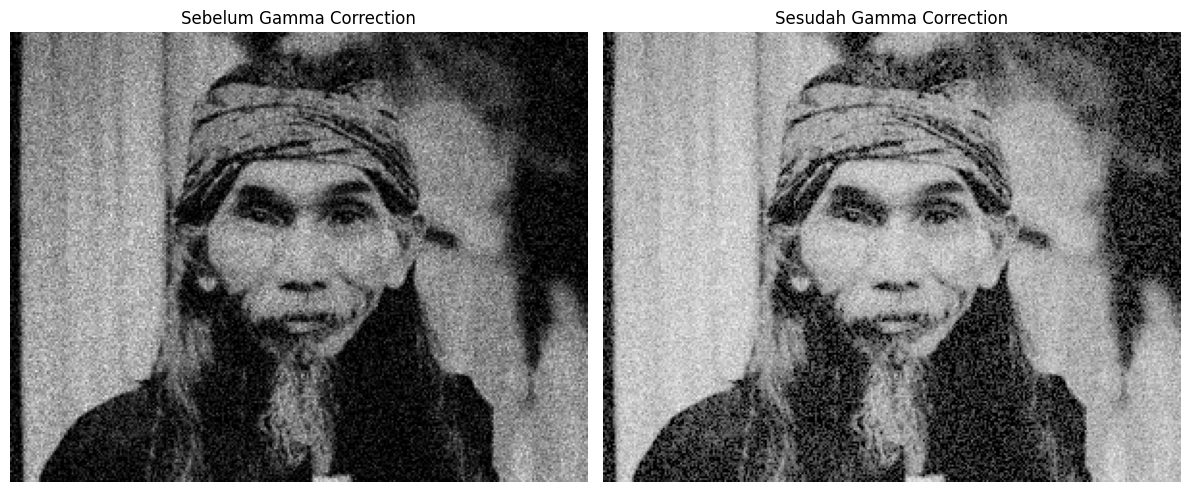

In [3]:
def gamma_correction(image, gamma=0.6):
    normalized = image.astype(np.float32) / 255.0

    corrected = np.power(normalized, gamma) * 255.0

    return np.clip(corrected, 0, 255).astype(np.uint8)


citra_gamma = gamma_correction(citra_noise, gamma=0.6)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(citra_noise, cmap="gray")
plt.title("Sebelum Gamma Correction")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(citra_gamma, cmap="gray")
plt.title("Sesudah Gamma Correction")
plt.axis("off")

plt.tight_layout()
plt.show()

**Sel 4 — Histogram Equalization**

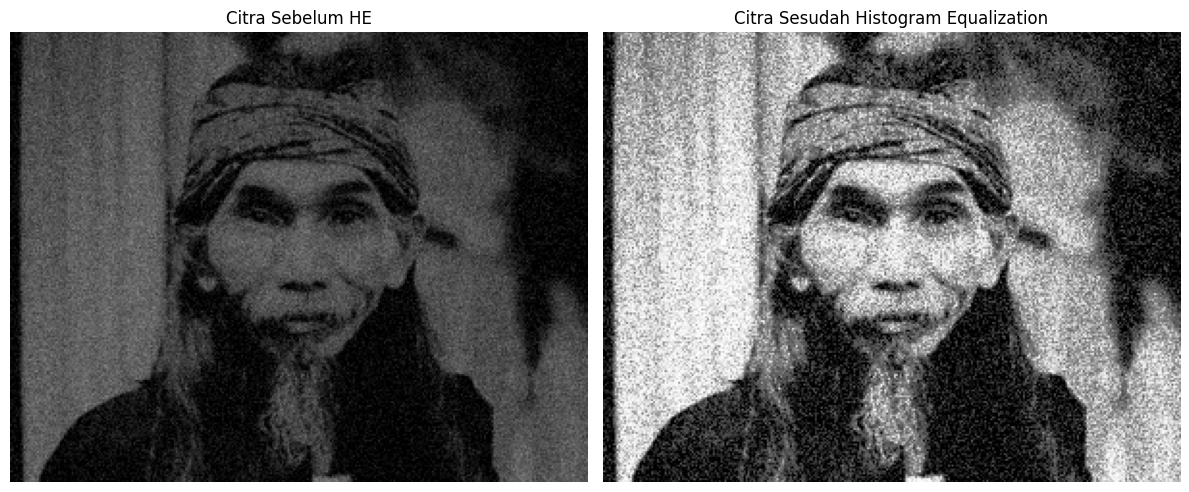

In [4]:
citra_he = cv2.equalizeHist(citra_noise)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(citra_noise, cmap="gray", vmin=0, vmax=255)
plt.title("Citra Sebelum HE")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(citra_he, cmap="gray", vmin=0, vmax=255)
plt.title("Citra Sesudah Histogram Equalization")
plt.axis("off")

plt.tight_layout()
plt.show()

**Sel 5 — CLAHE (Contrast Limited Adaptive Histogram Equalization)**

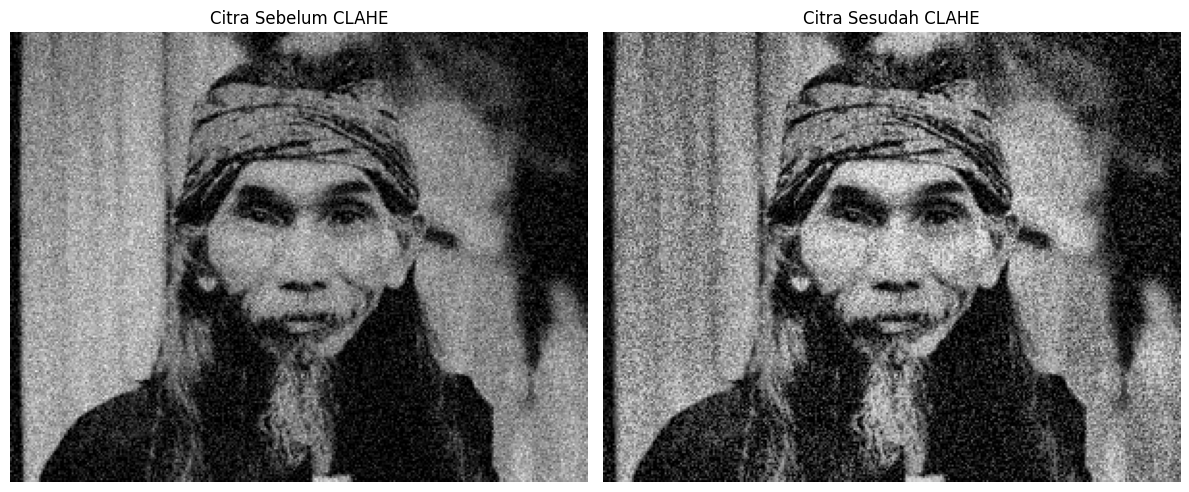

In [5]:
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

citra_clahe = clahe.apply(citra_noise)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(citra_noise, cmap="gray")
plt.title("Citra Sebelum CLAHE")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(citra_clahe, cmap="gray")
plt.title("Citra Sesudah CLAHE")
plt.axis("off")

plt.tight_layout()
plt.show()

**Sel 6 — Mengurangi noise dengan Gaussian Blur dan Median Filter**

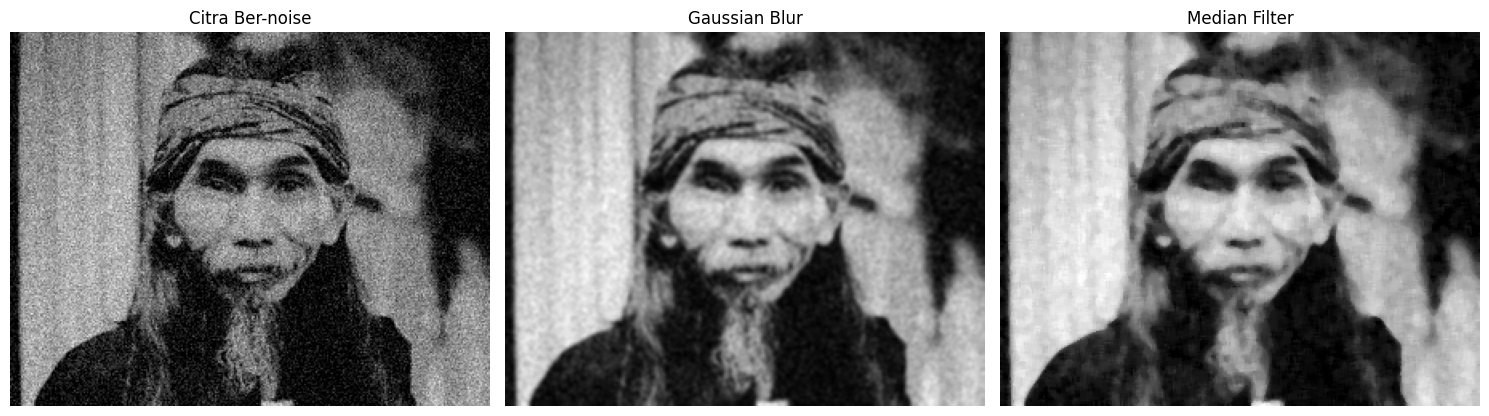

In [6]:
# Gaussian Blur
citra_gaussian = cv2.GaussianBlur(
    citra_noise,
    (5, 5),
    0
)

# Median Filter
citra_median = cv2.medianBlur(
    citra_noise,
    5
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(citra_noise, cmap="gray")
plt.title("Citra Ber-noise")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(citra_gaussian, cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(citra_median, cmap="gray")
plt.title("Median Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

**Sel 7 — Menggabungkan metode peningkatan kualitas citra**

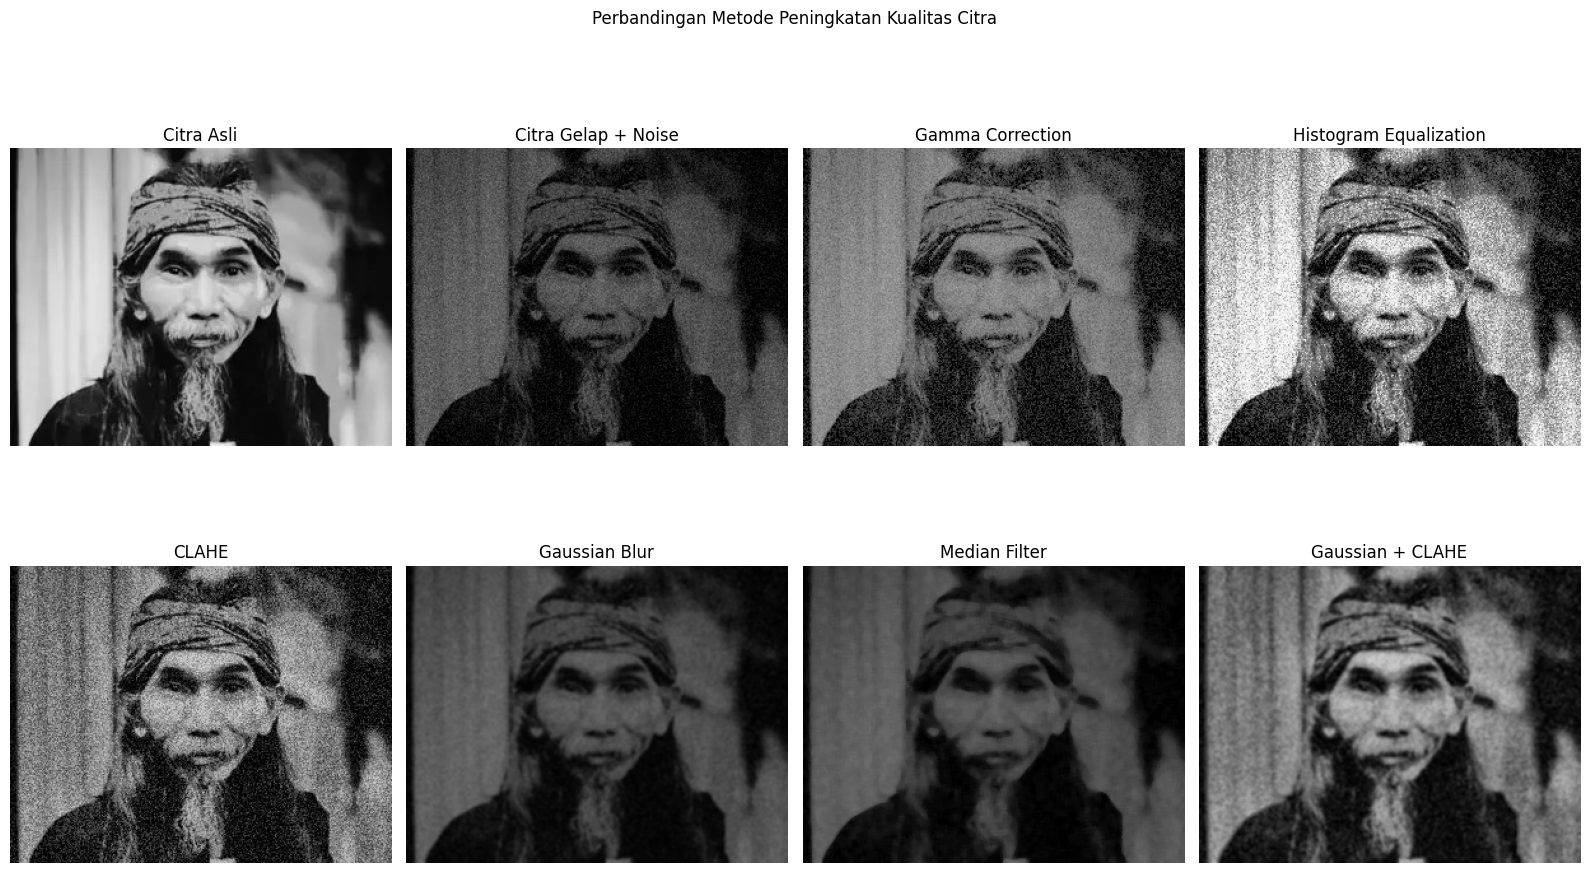

In [7]:
# Kombinasi: reduksi noise + CLAHE
citra_kombinasi = clahe.apply(citra_gaussian)

hasil_citra = {
    "Citra Asli": citra_asli,
    "Citra Gelap + Noise": citra_noise,
    "Gamma Correction": citra_gamma,
    "Histogram Equalization": citra_he,
    "CLAHE": citra_clahe,
    "Gaussian Blur": citra_gaussian,
    "Median Filter": citra_median,
    "Gaussian + CLAHE": citra_kombinasi
}

plt.figure(figsize=(16, 10))

for i, (nama, gambar) in enumerate(hasil_citra.items()):
    plt.subplot(2, 4, i + 1)
    plt.imshow(gambar, cmap="gray", vmin=0, vmax=255)
    plt.title(nama)
    plt.axis("off")

plt.suptitle("Perbandingan Metode Peningkatan Kualitas Citra")
plt.tight_layout()
plt.show()

**Sel 8 — Analisis histogram citra**

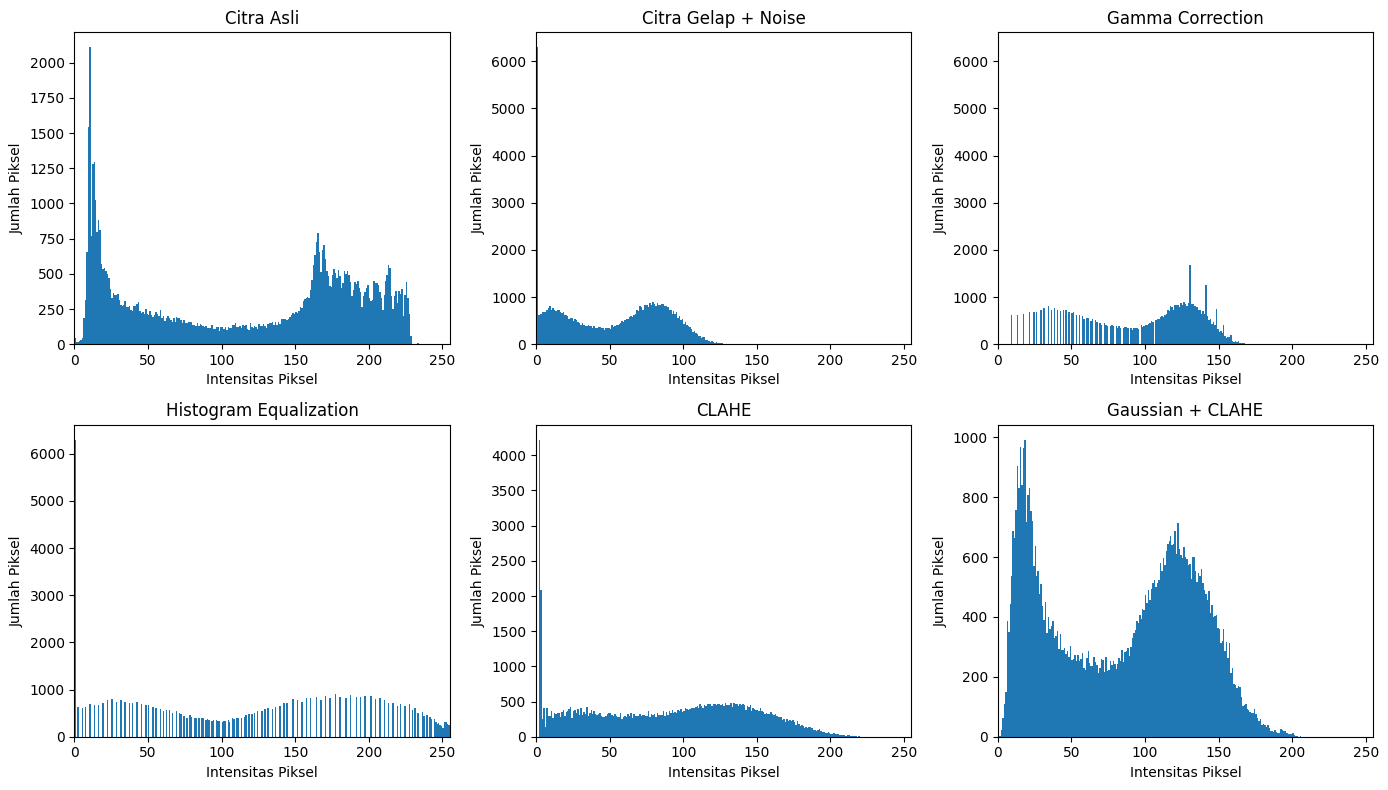

In [8]:
metode_analisis = {
    "Citra Asli": citra_asli,
    "Citra Gelap + Noise": citra_noise,
    "Gamma Correction": citra_gamma,
    "Histogram Equalization": citra_he,
    "CLAHE": citra_clahe,
    "Gaussian + CLAHE": citra_kombinasi
}

plt.figure(figsize=(14, 8))

for i, (nama, gambar) in enumerate(metode_analisis.items()):
    plt.subplot(2, 3, i + 1)

    plt.hist(
        gambar.ravel(),
        bins=256,
        range=(0, 256)
    )

    plt.title(nama)
    plt.xlabel("Intensitas Piksel")
    plt.ylabel("Jumlah Piksel")
    plt.xlim(0, 255)

plt.tight_layout()
plt.show()

**Sel 9 — Menghitung metrik kualitas citra**

In [9]:
def hitung_metrik(referensi, hasil):
    referensi_float = referensi.astype(np.float64)
    hasil_float = hasil.astype(np.float64)

    mse = np.mean((referensi_float - hasil_float) ** 2)

    if mse == 0:
        psnr = float("inf")
    else:
        psnr = 10 * np.log10((255 ** 2) / mse)

    nilai_ssim = ssim(
        referensi,
        hasil,
        data_range=255
    )

    rata_rata = np.mean(hasil_float)
    standar_deviasi = np.std(hasil_float)

    return mse, psnr, nilai_ssim, rata_rata, standar_deviasi


baris_hasil = []

for nama, gambar in hasil_citra.items():
    mse, psnr, nilai_ssim, rata, std = hitung_metrik(
        citra_asli,
        gambar
    )

    baris_hasil.append({
        "Metode": nama,
        "MSE": round(mse, 2),
        "PSNR (dB)": round(psnr, 2),
        "SSIM": round(nilai_ssim, 4),
        "Rata-rata Intensitas": round(rata, 2),
        "Standar Deviasi": round(std, 2)
    })

tabel_hasil = pd.DataFrame(baris_hasil)

display(
    tabel_hasil.sort_values(
        by="PSNR (dB)",
        ascending=False
    ).reset_index(drop=True)
)

,Metode,MSE,PSNR (dB),SSIM,Rata-rata Intensitas,Standar Deviasi
0,Citra Asli,0.00,inf,1.0000,114.74,76.00
1,Histogram Equalization,830.67,18.94,0.3677,117.18,79.25
2,Gamma Correction,2009.66,15.10,0.4529,88.24,47.54
3,Gaussian + CLAHE,2101.64,14.91,0.6986,83.73,50.03
4,CLAHE,2265.25,14.58,0.3829,88.13,56.01
5,Gaussian Blur,5949.16,10.39,0.5515,51.34,32.72
6,Citra Gelap + Noise,5966.66,10.37,0.3845,51.34,35.20
7,Median Filter,5995.12,10.35,0.5008,50.74,33.38


**Sel 10 — Menyimpan dan mengunduh hasil**

In [10]:
import os
import zipfile
from google.colab import files

folder_output = "/content/hasil_peningkatan_citra"
os.makedirs(folder_output, exist_ok=True)

# Simpan citra hasil
for nama, gambar in hasil_citra.items():
    nama_file = (
        nama.lower()
        .replace(" ", "_")
        .replace("+", "dan")
        .replace("/", "_")
    )

    cv2.imwrite(
        os.path.join(folder_output, nama_file + ".png"),
        gambar
    )

# Simpan tabel evaluasi
tabel_hasil.to_csv(
    os.path.join(folder_output, "evaluasi_kualitas.csv"),
    index=False
)

# Kemas seluruh hasil menjadi ZIP
file_zip = "/content/hasil_peningkatan_citra.zip"

with zipfile.ZipFile(file_zip, "w") as zipf:
    for nama_file in os.listdir(folder_output):
        path_file = os.path.join(folder_output, nama_file)
        zipf.write(path_file, arcname=nama_file)

print("Hasil pemrosesan berhasil disiapkan.")
files.download(file_zip)

Hasil pemrosesan berhasil disiapkan.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>